## Analysis

Final predictions and evaluation by language and model.


## Load and summarize

Dataset coverage by language, model, and evaluated questions.


In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

DATA_DIR = Path.cwd() / "data"

files = [
    path for path in sorted(DATA_DIR.glob("prediction_*.csv"))
]

language_names = {"en": "English", "sw": "Swahili"}
frames = []
for path in files:
    parts = path.stem.split("_")
    language_code, model = parts[1], parts[2]
    frame = pd.read_csv(path).assign(
        language=language_names[language_code],
        model=model,
    )
    frames.append(frame)

predictions = pd.concat(frames, ignore_index=True)
answer_pattern = re.compile(r"<answer>\s*(?:[1-4])\s*</answer>")
predictions["format_error"] = ~predictions["raw_output"].fillna("").str.contains(answer_pattern)

input_price = {"small": 0.02, "big": 0.40}
output_price = {"small": 0.04, "big": 0.40}
predictions["input_cost"] = (
    predictions["prompt_tokens"] * predictions["model"].map(input_price) / 1_000_000
)
predictions["output_cost"] = (
    predictions["completion_tokens"] * predictions["model"].map(output_price) / 1_000_000
)

overview = predictions.groupby(["language", "model"], as_index=False).agg(
    n=("question_id", "count")
)
overview

,language,model,n
0,English,big,900
1,English,small,900
2,Swahili,big,900
3,Swahili,small,900


## Model accuracy

Accuracy, sample standard deviation, and 95% Wilson interval.


In [2]:
def wilson_interval(successes, trials, z=1.96):
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    centre = (proportion + z**2 / (2 * trials)) / denominator
    margin = z * (proportion * (1 - proportion) / trials + z**2 / (4 * trials**2)) ** 0.5 / denominator
    return centre - margin, centre + margin

accuracy_rows = []
for (language, model), group in predictions.groupby(["language", "model"]):
    n = len(group)
    correct = int(group["correct"].sum())
    low, high = wilson_interval(correct, n)
    accuracy_rows.append({
        "language": language,
        "model": model,
        "n": n,
        "mean_accuracy": group["correct"].mean(),
        "sd_accuracy": group["correct"].std(ddof=1),
        "format_error_rate": group["format_error"].mean(),
        "95ci_accuracy": f"[{low:.1%}, {high:.1%}]",
    })

accuracy_table = pd.DataFrame(accuracy_rows)
display(accuracy_table.style.format({
    "mean_accuracy": "{:.1%}",
    "sd_accuracy": "{:.3f}",
    "format_error_rate": "{:.1%}",
}))

format_errors = predictions.loc[
    predictions["format_error"],
    ["language", "model", "question_id", "gold", "pred", "raw_output"],
].copy()
print(f"Format-error cases: {len(format_errors)}")
for _, case in format_errors.iterrows():
    print(f"{case['language']} / {case['model']} / {case['question_id']}")


,language,model,n,mean_accuracy,sd_accuracy,format_error_rate,95ci_accuracy
0,English,big,900,96.1%,0.193,0.0%,"[94.6%, 97.2%]"
1,English,small,900,90.8%,0.290,0.4%,"[88.7%, 92.5%]"
2,Swahili,big,900,88.6%,0.319,0.0%,"[86.3%, 90.5%]"
3,Swahili,small,900,61.3%,0.487,1.3%,"[58.1%, 64.5%]"


Format-error cases: 16
English / small / q_149
English / small / q_215
English / small / q_680
English / small / q_857
Swahili / small / q_22
Swahili / small / q_156
Swahili / small / q_233
Swahili / small / q_286
Swahili / small / q_438
Swahili / small / q_510
Swahili / small / q_557
Swahili / small / q_620
Swahili / small / q_656
Swahili / small / q_734
Swahili / small / q_757
Swahili / small / q_864


## Token usage and inference cost

Token usage and inference cost.


In [3]:
token_rows = []
for (language, model), group in predictions.groupby(["language", "model"]):
    total_tokens = group["prompt_tokens"] + group["completion_tokens"]
    token_rows.append({
        "language": language,
        "model": model,
        "n": len(group),
        "total_input_tokens": group["prompt_tokens"].sum(),
        "total_output_tokens": group["completion_tokens"].sum(),
        "total_tokens": total_tokens.sum(),
        "mean_in_tokens": group["prompt_tokens"].mean(),
        "sd_in_tokens": group["prompt_tokens"].std(ddof=1),
        "mean_out_tokens": group["completion_tokens"].mean(),
        "sd_out_tokens": group["completion_tokens"].std(ddof=1),
        "mean_total_tokens": total_tokens.mean(),
        "sd_total_tokens": total_tokens.std(ddof=1),
    })

token_table = pd.DataFrame(token_rows)
display( token_table.style.format({
    "total_input_tokens": "{:,.0f}",
    "total_output_tokens": "{:,.0f}",
    "total_tokens": "{:,.0f}",
    "mean_in_tokens": "{:.1f}",
    "sd_in_tokens": "{:.1f}",
    "mean_out_tokens": "{:.1f}",
    "sd_out_tokens": "{:.1f}",
    "mean_total_tokens": "{:.1f}",
    "sd_total_tokens": "{:.1f}",
}))

cost_rows = []
for (language, model), group in predictions.groupby(["language", "model"]):
    total_cost = group["input_cost"] + group["output_cost"]
    cost_rows.append({
        "language": language,
        "model": model,
        "n": len(group),
        "total_input_cost": group["input_cost"].sum(),
        "total_output_cost": group["output_cost"].sum(),
        "total_costs": total_cost.sum(),
        "mean_in_cost": group["input_cost"].mean(),
        "sd_in_cost": group["input_cost"].std(ddof=1),
        "mean_out_cost": group["output_cost"].mean(),
        "sd_out_cost": group["output_cost"].std(ddof=1),
        "mean_total_cost": (group["input_cost"] + group["output_cost"]).mean(),
        "sd_total_cost": (group["input_cost"] + group["output_cost"]).std(ddof=1),
    })

cost_table = pd.DataFrame(cost_rows)
display(cost_table.style.format({
    "total_input_cost": "${:,.6f}",
    "total_output_cost": "${:,.6f}",
    "total_costs": "${:,.6f}",
    "mean_in_cost": "${:.6f}",
    "sd_in_cost": "${:.6f}",
    "mean_out_cost": "${:.6f}",
    "sd_out_cost": "${:.6f}",
    "mean_total_cost": "${:.6f}",
    "sd_total_cost": "${:.6f}",
}))


,language,model,n,total_input_tokens,total_output_tokens,total_tokens,mean_in_tokens,sd_in_tokens,mean_out_tokens,sd_out_tokens,mean_total_tokens,sd_total_tokens
0,English,big,900,"211,711","180,324","392,035",235.2,36.3,200.4,69.0,435.6,83.0
1,English,small,900,"209,446","133,678","343,124",232.7,36.1,148.5,72.0,381.2,86.8
2,Swahili,big,900,"358,837","7,990","366,827",398.7,71.7,8.9,0.5,407.6,71.7
3,Swahili,small,900,"355,142","10,372","365,514",394.6,71.7,11.5,32.4,406.1,80.3


,language,model,n,total_input_cost,total_output_cost,total_costs,mean_in_cost,sd_in_cost,mean_out_cost,sd_out_cost,mean_total_cost,sd_total_cost
0,English,big,900,$0.084684,$0.072130,$0.156814,$0.000094,$0.000015,$0.000080,$0.000028,$0.000174,$0.000033
1,English,small,900,$0.004189,$0.005347,$0.009536,$0.000005,$0.000001,$0.000006,$0.000003,$0.000011,$0.000003
2,Swahili,big,900,$0.143535,$0.003196,$0.146731,$0.000159,$0.000029,$0.000004,$0.000000,$0.000163,$0.000029
3,Swahili,small,900,$0.007103,$0.000415,$0.007518,$0.000008,$0.000001,$0.000000,$0.000001,$0.000008,$0.000002


## Router Predictions

Preview and summary of `router_predictions.csv`.

In [9]:
router_predictions_path = DATA_DIR / "router_predictions.csv"
router_predictions = pd.read_csv(router_predictions_path)

required_router_columns = {
    "question_id", "language", "label", "fold",
    "p_big_blind", "theta_blind", "p_big_aware", "theta_aware",
}
missing_router_columns = required_router_columns.difference(router_predictions.columns)
if missing_router_columns:
    raise ValueError(f"router predictions are missing columns: {sorted(missing_router_columns)}")

if router_predictions[["question_id", "language"]].duplicated().any():
    raise ValueError("router_predictions.csv contains duplicate question/language rows")
if router_predictions["question_id"].isna().any() or router_predictions["language"].isna().any():
    raise ValueError("router_predictions.csv contains missing query identifiers")

probability_columns = ["p_big_blind", "p_big_aware"]
if router_predictions[probability_columns].isna().any().any():
    raise ValueError("router probabilities contain missing values")
probabilities_in_range = router_predictions[probability_columns].ge(0).all().all() and router_predictions[probability_columns].le(1).all().all()
if not probabilities_in_range:
    raise ValueError("router probabilities must be between 0 and 1")

check_summary = pd.DataFrame({
    "rows": [len(router_predictions)],
    "unique_questions": [router_predictions["question_id"].nunique()],
    "languages": [", ".join(sorted(router_predictions["language"].unique()))],
    "folds": [router_predictions["fold"].nunique()],
    "missing_values": [int(router_predictions.isna().sum().sum())],
})
display(check_summary)
sample_predictions = (
    router_predictions
    .groupby("language", group_keys=False)
    .sample(n=5, random_state=42)
    .sort_values(["language", "question_id"])
    .reset_index(drop=True)
)

display(sample_predictions)


,rows,unique_questions,languages,folds,missing_values
0,1800,900,"en, sw",5,0


,question_id,language,label,fold,p_big_blind,theta_blind,p_big_aware,theta_aware
0,q_231,en,0,1,0.123307,0.12,0.038290,0.06
1,q_39,en,0,1,0.183383,0.12,0.097542,0.06
2,q_588,en,0,1,0.182492,0.12,0.088888,0.06
3,q_70,en,0,1,0.196592,0.12,0.103026,0.06
4,q_827,en,0,0,0.163363,0.14,0.069194,0.04
5,q_135,sw,0,3,0.205065,0.13,0.300496,0.05
6,q_403,sw,0,0,0.162887,0.14,0.199642,0.04
7,q_408,sw,0,0,0.172122,0.14,0.296127,0.04
8,q_592,sw,0,1,0.209852,0.12,0.365121,0.06
9,q_616,sw,0,4,0.257654,0.12,0.423669,0.05


## Router Evaluation

Metrics from `evaluation_results.csv`, as defined in `docs/metrics.md`.


In [5]:
evaluation_path = Path.cwd() / "data" / "evaluation_results.csv"
evaluation = pd.read_csv(evaluation_path)

focus_metrics = [
    "AvgAcc", "Gain@B", "Gain@R", "Gap@O", "PerfGain",
    "CostSave", "ParetoDist", "Recall@1",
]
required_columns = {"router", "Cost", *focus_metrics, "Acc_en", "Acc_sw"}
missing_columns = required_columns.difference(evaluation.columns)
if missing_columns:
    raise ValueError(f"evaluation results are missing columns: {sorted(missing_columns)}")
if evaluation["router"].duplicated().any():
    raise ValueError("evaluation results must contain one row per router")

metric_table = evaluation.set_index("router")[focus_metrics].copy()
display(metric_table.style.format({metric: "{:.2%}" for metric in focus_metrics}))


,AvgAcc,Gain@B,Gain@R,Gap@O,PerfGain,CostSave,ParetoDist,Recall@1
router,,,,,,,,
always_small,76.06%,-18.14%,-10.51%,19.65%,-17.63%,0.00%,0.00%,nan%
always_big,92.33%,0.00%,10.51%,1.90%,0.00%,0.00%,0.00%,nan%
language_rule,89.67%,-2.77%,7.65%,4.64%,-2.89%,0.00%,0.00%,nan%
oracle,94.11%,1.94%,12.69%,0.00%,1.93%,77.31%,0.00%,nan%
router_blind,92.28%,-0.06%,10.43%,1.97%,0.00%,0.17%,0.03%,76.06%
router_aware,92.22%,-0.12%,10.39%,2.02%,0.00%,1.04%,0.05%,76.06%


## Accuracy by language

Router accuracy by language, ordered by cost.

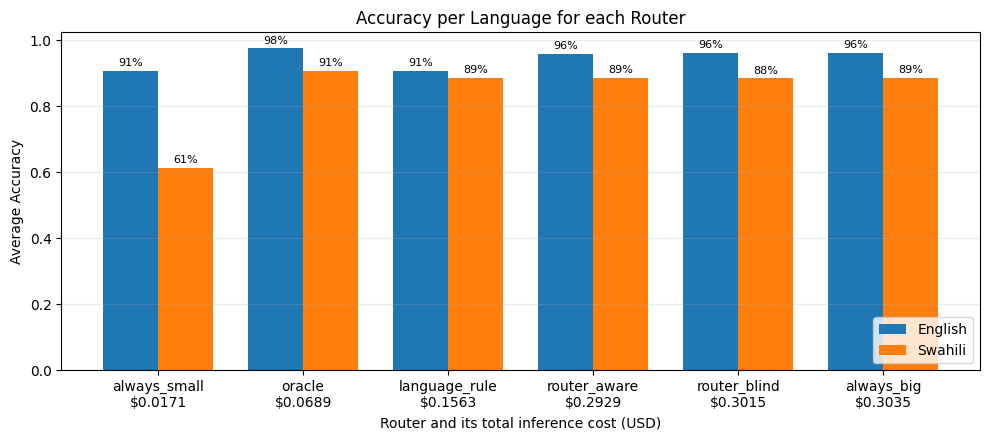

In [27]:
df = evaluation.set_index("router")
order = df.sort_values("Cost").index  # cheapest on the left

fig, ax = plt.subplots(figsize=(10, 4.5))
x, w = np.arange(len(order)), 0.38
for i, (code, name) in enumerate([("en", "English"), ("sw", "Swahili")]):
    vals = df.loc[order, f"Acc_{code}"]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels([f"{r}\n${df.loc[r, 'Cost']:.4f}" for r in order])
ax.set_xlabel("Router and its total inference cost (USD)")
ax.set_ylabel("Average Accuracy")
ax.set_title("Accuracy per Language for each Router")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## Accuracy vs. cost

Router accuracy and cost by language; the dashed line shows random routing.

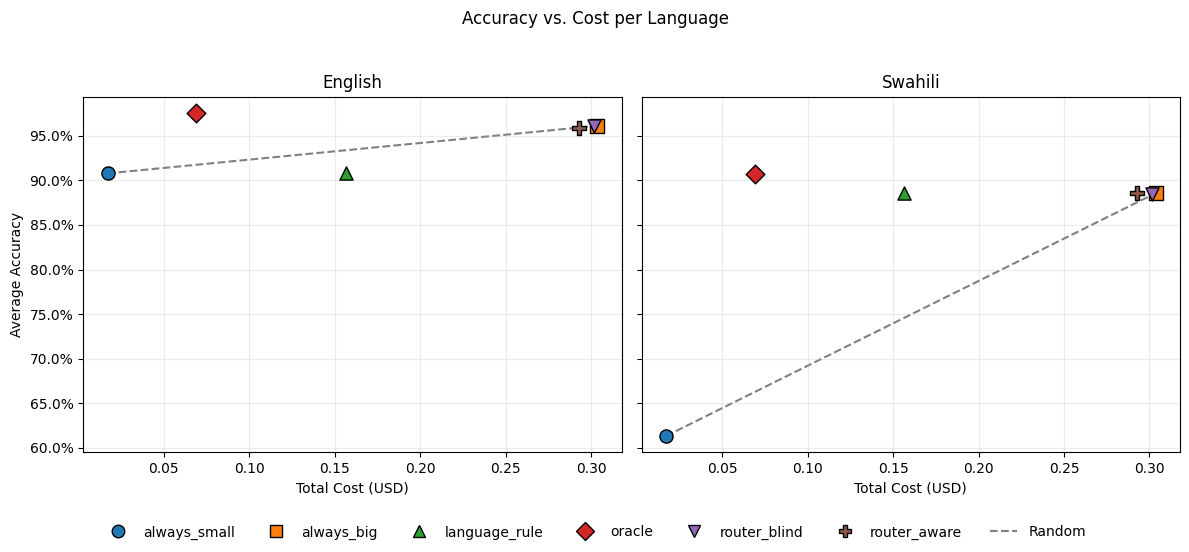

In [ ]:
df = evaluation.set_index("router")
small, big = df.loc["always_small"], df.loc["always_big"]

markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
colors = plt.cm.tab10(np.arange(len(df)))
style = {r: (markers[i % len(markers)], colors[i]) for i, r in enumerate(df.index)}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, (code, name) in zip(axes, [("en", "English"), ("sw", "Swahili")]):
    # Dashed line: randomly mixing the small and the big model
    ax.plot([small["Cost"], big["Cost"]], [small[f"Acc_{code}"], big[f"Acc_{code}"]],
            "--", color="gray", zorder=1)
    for r in df.index:
        m, c = style[r]
        ax.scatter(df.loc[r, "Cost"], df.loc[r, f"Acc_{code}"], marker=m, color=c,
                   s=90, edgecolor="black", zorder=3)
    ax.set_title(name)
    ax.set_xlabel("Total Cost (USD)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Average Accuracy")

handles = [plt.Line2D([], [], marker=style[r][0], color=style[r][1], linestyle="", markersize=9,
                      markeredgecolor="black", label=r) for r in df.index]
handles.append(plt.Line2D([], [], linestyle="--", color="gray", label="Random"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
fig.suptitle("Accuracy vs. Cost per Language")
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

## Router gains vs. language rule

Three metrics compare routers with the language rule; higher is better.

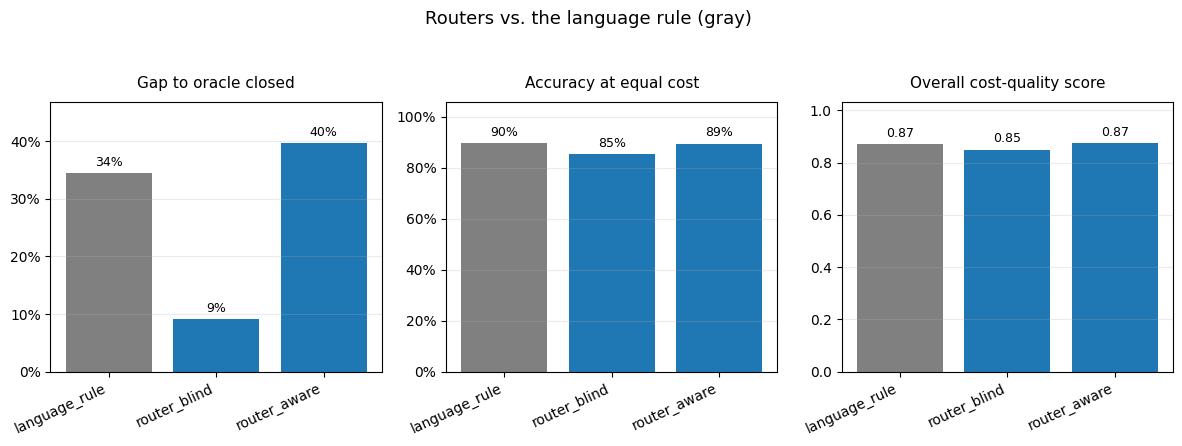

In [ ]:
df = evaluation.set_index("router")
compared = df.drop(index=["always_small", "always_big", "oracle", "random"], errors="ignore")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, (metric, title, fmt, pct) in zip(axes, [
    ("GapClosed", "Gap to oracle closed", "{:.0%}", True),
    ("Acc@Budget", "Accuracy at equal cost", "{:.0%}", True),
    ("AIQ", "Overall cost-quality score", "{:.2f}", False),
]):
    vals = compared[metric]
    colors = ["gray" if r == "language_rule" else "tab:blue" for r in vals.index]
    bars = ax.bar(vals.index, vals, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals], fontsize=9, padding=3)
    ax.set_ylim(0, vals.max() * 1.18)  # headroom so labels never touch the title
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title, fontsize=11, pad=10)
    ax.tick_params(axis="x", rotation=25)
    for tick in ax.get_xticklabels():
        tick.set_ha("right")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Routers vs. the language rule (gray)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## Routing diversity and correctness

Choice diversity versus correct low-cost selections.

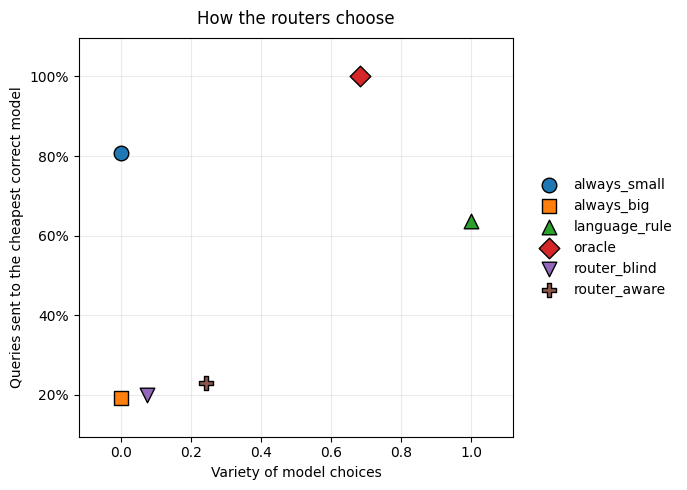

In [ ]:
df = evaluation.set_index("router")

markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
colors = plt.cm.tab10(np.arange(len(df)))
style = {r: (markers[i % len(markers)], colors[i]) for i, r in enumerate(df.index)}

fig, ax = plt.subplots(figsize=(7, 5))
for r in df.index:
    m, c = style[r]
    ax.scatter(df.loc[r, "SelectionEntropy"], df.loc[r, "OptimalSelectionRatio"],
               marker=m, color=c, s=110, edgecolor="black", zorder=3, label=r)

ax.margins(0.12)  # padding so points never sit on the frame
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Variety of model choices")
ax.set_ylabel("Queries sent to the cheapest correct model")
ax.set_title("How the routers choose", fontsize=12, pad=10)
ax.grid(alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()

## Router summary

Cost savings, language-specific accuracy changes, fairness gap, and routing gains.

In [16]:
df = evaluation.set_index("router")
big, rule = df.loc["always_big"], df.loc["language_rule"]

summary = pd.DataFrame({
    "cost_saved_vs_big": 1 - df["Cost"] / big["Cost"],
    "dAcc_en_pp": (df["Acc_en"] - big["Acc_en"]) * 100,
    "dAcc_sw_pp": (df["Acc_sw"] - big["Acc_sw"]) * 100,
    "language_gap_pp": (df["Acc_en"] - df["Acc_sw"]) * 100,
    "GapClosed": df["GapClosed"],
    "vs_rule_at_budget_pp": (df["Acc@Budget"] - rule["AvgAcc"]) * 100,
}).sort_values("cost_saved_vs_big", ascending=False)

display(summary.style.format({
    "cost_saved_vs_big": "{:.1%}",
    "dAcc_en_pp": "{:+.1f}",
    "dAcc_sw_pp": "{:+.1f}",
    "language_gap_pp": "{:.1f}",
    "GapClosed": "{:.1%}",
    "vs_rule_at_budget_pp": "{:+.1f}",
}).background_gradient(subset=["dAcc_en_pp", "dAcc_sw_pp"], cmap="RdYlGn", vmin=-10, vmax=0))

,cost_saved_vs_big,dAcc_en_pp,dAcc_sw_pp,language_gap_pp,GapClosed,vs_rule_at_budget_pp
router,,,,,,
always_small,94.4%,-5.3,-27.2,29.4,0.0%,-5.7
oracle,77.3%,+1.4,+2.1,6.9,100.0%,+4.4
language_rule,48.5%,-5.3,+0.0,2.2,34.4%,+0.0
router_aware,3.5%,-0.2,+0.0,7.3,39.7%,-0.2
router_blind,0.7%,+0.0,-0.1,7.7,9.2%,-4.4
always_big,0.0%,+0.0,+0.0,7.6,0.0%,-5.7
